# sideslip analysis 2

In [2]:
# Import necessary libraries
import os
import sys
# Add the utils folder to the system path so we can import custom modules
sys.path.append(os.path.abspath(os.path.join("..")))
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names

# Set the plotting style for better-looking visualizations
plt.style.available
plt.style.use('seaborn-v0_8')

In [3]:
seed_everything(42)  # for reproducibility

In [4]:
print("Loading train data...")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path = "datasets_challenge/train",  # Path to training data
    train_ratio = 0.8,  # Use 80% for training, 20% for validation
    batchsize = 512,  # Number of samples per batch
    columns_to_standardize = feature_names,  # Option to specify which columns to standardize
    columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],  # Remove these from features
    sequence_length = 20,  # Number of time steps in each sequence (t-19 to t0)
    threshold = True,  # Enable velocity thresholding
    threshold_value = 3.0,  # Only keep samples where vehicle speed > 3 m/s
    threshold_column = "vxCG",  # Column to apply threshold on (longitudinal velocity)
    target = "sideSlip",  # The variable we want to predict
    scaling = True,  # Apply standardization to features
    seed = 42,  # Random seed for train/val split
)

Loading train data...
datasets_challenge/train\train_part_001.csv
datasets_challenge/train\train_part_002.csv
datasets_challenge/train\train_part_003.csv
datasets_challenge/train\train_part_004.csv
datasets_challenge/train\train_part_005.csv
datasets_challenge/train\train_part_006.csv
datasets_challenge/train\train_part_007.csv
datasets_challenge/train\train_part_008.csv
datasets_challenge/train\train_part_009.csv
datasets_challenge/train\train_part_010.csv
datasets_challenge/train\train_part_011.csv
datasets_challenge/train\train_part_012.csv
datasets_challenge/train\train_part_013.csv
datasets_challenge/train\train_part_014.csv
datasets_challenge/train\train_part_015.csv
datasets_challenge/train\train_part_016.csv
datasets_challenge/train\train_part_017.csv
datasets_challenge/train\train_part_018.csv
datasets_challenge/train\train_part_019.csv
datasets_challenge/train\train_part_020.csv
datasets_challenge/train\train_part_021.csv
datasets_challenge/train\train_part_022.csv


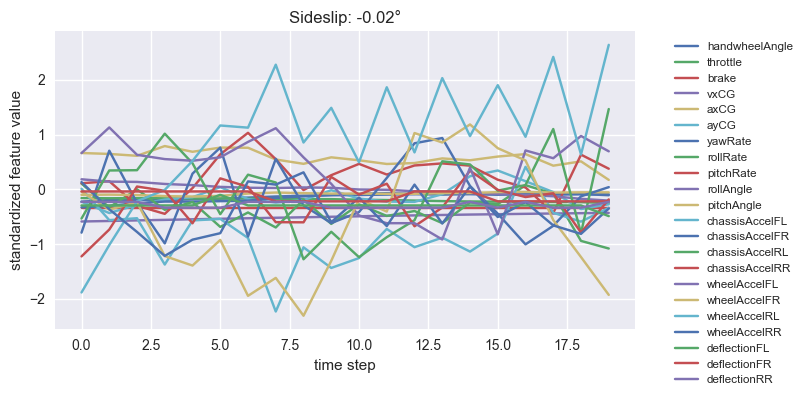

In [5]:
# Get one batch of data from the training dataloader
X, y = next(iter(train_dataloader))

# Visualize the first sample in the batch
plt.figure(figsize=(8,4))
plt.plot(X[0,:,:], label=feature_names)  # Plot all 22 features over 20 time steps
plt.title("Sideslip: "+str(round(y[0].item(),2))+"°")  # Show the target value
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.xlabel("time step")
plt.ylabel("standardized feature value")
plt.show()

In [6]:
num_features = len(feature_names)
print("Num features:", num_features)

Num features: 22


# bidirectional lstm model

In [7]:
class BiLSTMRegressor(nn.Module):
    def __init__(self,
                 input_size,
                 hidden_size=128,
                 num_layers=2,
                 fc_units=64,
                 dropout=0.3,
                 activation_fct=nn.ReLU()):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=True
        )

        # since bidirectional -> hidden size doubles
        self.fc = nn.Sequential(
            nn.Linear(hidden_size * 2, fc_units),
            activation_fct,
            nn.Dropout(dropout),
            nn.Linear(fc_units, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        last_timestep = out[:, -1, :]  # last time step features from both directions
        y_hat = self.fc(last_timestep)
        return y_hat

In [10]:
# Set device for computation (CPU or GPU)
device = "cpu"  # Change to "cuda" if you have a GPU available

model = BiLSTMRegressor(input_size=num_features).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=4)
criterion = nn.MSELoss()
print(model)

BiLSTMRegressor(
  (lstm): LSTM(22, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (fc): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [11]:
# Training configuration
num_epochs = 30  # Maximum number of training epochs
early_stop_thresh = 10  # Stop if no improvement for this many epochs
best_loss = np.inf  # Initialize with infinity
best_epoch = -1
best_model_state = None  # Will store the best model weights

# Lists to track training progress
train_curve = []
val_curve = []

for epoch in range(num_epochs):
    running_loss = 0
    
    # ========== TRAINING PHASE ==========
    model.train()  # Set model to training mode (enables dropout)
    for step, (x, y) in enumerate(train_dataloader):
        # Move data to device and reshape target
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        
        optimizer.zero_grad()  # Reset gradients from previous iteration
        pred = model(X)  # Forward pass: get predictions
        train_loss = criterion(pred, y)  # Calculate loss
        running_loss += train_loss.item()
        train_loss.backward()  # Backward pass: compute gradients
        optimizer.step()  # Update model weights
    
    avg_train_loss = running_loss / step
    train_curve.append(avg_train_loss)

    # ========== VALIDATION PHASE ==========
    model.eval()  # Set model to evaluation mode (disables dropout)
    running_val_loss = 0
    with torch.no_grad():  # Disable gradient computation (saves memory and computation)
        for val_step, (x, y) in enumerate(val_dataloader):
            X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
            val_loss = criterion(model(X_val), y_val)
            running_val_loss += val_loss.item()
    
    avg_val_loss = running_val_loss / val_step
    val_curve.append(avg_val_loss)
    
    # Print epoch summary
    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.5f} | Val Loss: {avg_val_loss:.5f}", end="")
    
    # ========== EARLY STOPPING & MODEL CHECKPOINTING ==========
    if avg_val_loss < best_loss:
        # New best model found - save it!
        best_loss = avg_val_loss
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': best_loss
        }, 'best_model.pth')
        print(f"  → New best validation loss: {best_loss:.5f}")
    elif epoch - best_epoch > early_stop_thresh:
        # No improvement for too long - stop training
        print(f"  → Early stopping triggered at epoch {epoch+1} (best epoch: {best_epoch+1})")
        break
    else:
        print("")

# ========== LOAD BEST MODEL ==========
if best_epoch != -1:
    checkpoint = torch.load('best_model.pth', weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"\n✓ Best model from epoch {best_epoch+1} loaded (Val Loss: {best_loss:.5f})")
else:
    print("\n⚠ No improvement found, using current model")

Epoch 1/30 | Train Loss: 0.42370 | Val Loss: 0.10707  → New best validation loss: 0.10707
Epoch 2/30 | Train Loss: 0.12669 | Val Loss: 0.07802  → New best validation loss: 0.07802
Epoch 3/30 | Train Loss: 0.11171 | Val Loss: 0.07408  → New best validation loss: 0.07408
Epoch 4/30 | Train Loss: 0.10378 | Val Loss: 0.06707  → New best validation loss: 0.06707
Epoch 5/30 | Train Loss: 0.09624 | Val Loss: 0.06310  → New best validation loss: 0.06310
Epoch 6/30 | Train Loss: 0.09236 | Val Loss: 0.05487  → New best validation loss: 0.05487
Epoch 7/30 | Train Loss: 0.08365 | Val Loss: 0.04978  → New best validation loss: 0.04978
Epoch 8/30 | Train Loss: 0.08505 | Val Loss: 0.05301
Epoch 9/30 | Train Loss: 0.07979 | Val Loss: 0.04638  → New best validation loss: 0.04638
Epoch 10/30 | Train Loss: 0.07668 | Val Loss: 0.05352
Epoch 11/30 | Train Loss: 0.07791 | Val Loss: 0.04629  → New best validation loss: 0.04629
Epoch 12/30 | Train Loss: 0.07773 | Val Loss: 0.04973
Epoch 13/30 | Train Loss: 0.

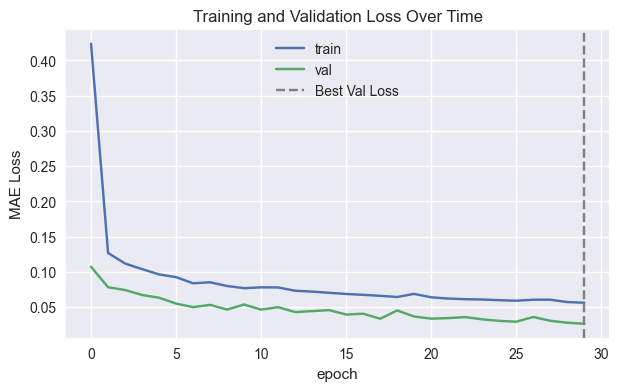

In [12]:
# Visualize training progress
plt.figure(figsize=(7, 4))
plt.plot(train_curve, label="train")
plt.plot(val_curve, label="val")
plt.axvline(x=best_epoch, color='gray', linestyle='--', label='Best Val Loss')
plt.xlabel("epoch")
plt.ylabel("MAE Loss")
plt.legend()
plt.title("Training and Validation Loss Over Time")
plt.show()

## Verification Step

In [13]:
# Evaluate the loaded model on validation set
model.eval()
running_val_loss = 0
with torch.no_grad():
    for val_step, (x, y) in enumerate(val_dataloader):
        X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
        val_loss = criterion(model(X_val), y_val)
        running_val_loss += val_loss.item()

avg_val_loss = running_val_loss / val_step

print(f"Final Evaluation on Validation Set - MAE Loss: {avg_val_loss:.5f}")

Final Evaluation on Validation Set - MAE Loss: 0.02627


In [14]:
# Load complete training data (unshuffled) for visualization
# This uses the same preprocessing pipeline to ensure consistency
train_dataloader_unshuffled = load_test_data(
    test_path="datasets_challenge/train",
    batchsize=512,
    pipeline=pipeline,  # Use the same preprocessing as training
    load_anonymized_data=False  # We have ground truth for training data
)

datasets_challenge/train\train_part_001.csv
datasets_challenge/train\train_part_002.csv
datasets_challenge/train\train_part_003.csv
datasets_challenge/train\train_part_004.csv
datasets_challenge/train\train_part_005.csv
datasets_challenge/train\train_part_006.csv
datasets_challenge/train\train_part_007.csv
datasets_challenge/train\train_part_008.csv
datasets_challenge/train\train_part_009.csv
datasets_challenge/train\train_part_010.csv
datasets_challenge/train\train_part_011.csv
datasets_challenge/train\train_part_012.csv
datasets_challenge/train\train_part_013.csv
datasets_challenge/train\train_part_014.csv
datasets_challenge/train\train_part_015.csv
datasets_challenge/train\train_part_016.csv
datasets_challenge/train\train_part_017.csv
datasets_challenge/train\train_part_018.csv
datasets_challenge/train\train_part_019.csv
datasets_challenge/train\train_part_020.csv
datasets_challenge/train\train_part_021.csv
datasets_challenge/train\train_part_022.csv


In [15]:
import plotly.graph_objects as go

# Set model to evaluation mode
model.eval()

# Storage for predictions and ground truth
total_loss = 0  
preds = []
ground_truths = []

# Generate predictions for all training data
with torch.no_grad():
    for step, (x, y) in enumerate(train_dataloader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])

        pred = model(X)
        loss = criterion(pred, y)
        total_loss += loss.item()
        
        # Store predictions and ground truth
        preds.append(pred.reshape(-1).cpu().numpy())
        ground_truths.append(y.reshape(-1).cpu().numpy())

    print(f"Avg. Loss: {total_loss/step}")
    
    # Concatenate all batches into single arrays
    ground_truths = np.concatenate(ground_truths)
    preds = np.concatenate(preds)

# Create interactive plot
fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='truth', line=dict(color='blue')))
fig.add_trace(go.Scatter(y=preds.flatten(), mode='lines', name='pred', line=dict(color='red'), opacity=0.8))
fig.update_layout(
    title='Ground Truth vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500
)
fig.show()

Avg. Loss: 0.025085035962670036


In [16]:
print("\nLoading test data...")
test_dataloader = load_test_data(test_path = "datasets_challenge/test",
                                 batchsize = 512,
                                 pipeline = pipeline, 
                                 load_anonymized_data=True)


Loading test data...
datasets_challenge/test\test_part_001.csv
datasets_challenge/test\test_part_002.csv
datasets_challenge/test\test_part_003.csv
datasets_challenge/test\test_part_004.csv
datasets_challenge/test\test_part_005.csv
datasets_challenge/test\test_part_006.csv
datasets_challenge/test\test_part_007.csv
datasets_challenge/test\test_part_008.csv
datasets_challenge/test\test_part_009.csv
datasets_challenge/test\test_part_010.csv
datasets_challenge/test\test_part_011.csv


In [17]:
# Generate predictions on test set
model.eval()
total_loss = 0  
test_preds = []
test_ground_truths = []  # Will contain placeholder values (all zeros)

with torch.no_grad():
    for step, (x, y) in enumerate(test_dataloader):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])

        pred = model(X)
        loss = criterion(pred, y)
        # Note: loss is meaningless here since y contains placeholder values
        
        # Store predictions
        test_preds.append(pred.reshape(-1).cpu().numpy())
        test_ground_truths.append(y.reshape(-1).cpu().numpy())

    # Concatenate all batches
    test_ground_truths = np.concatenate(test_ground_truths)
    test_preds = np.concatenate(test_preds)
    
print("Shape of Predictions", test_preds.shape)

Shape of Predictions (49328,)


In [18]:
# Visualize test predictions (note: test_ground_truths are just zeros here)
fig = go.Figure()
fig.add_trace(go.Scatter(y=test_ground_truths, mode='lines', name='placeholder (zeros)', 
                         line=dict(color='blue')))
fig.add_trace(go.Scatter(y=test_preds.flatten(), mode='lines', name='predictions', 
                         line=dict(color='red'), opacity=0.8))
fig.update_layout(
    title='Test Set: Placeholder vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500
)
fig.show()

In [19]:
# Save predictions in the required format for submission
y_pred = pd.DataFrame({"predicted_sideslip": test_preds})
y_pred["id"] = range(len(test_preds))  # Add sample IDs (0 to 49327)

# Save to CSV file
y_pred.to_csv("predictions.csv", index=False)

print(f"✓ Predictions saved to 'predictions.csv'")
print(f"✓ Total samples: {len(test_preds)}")
print(f"✓ Ready for submission to the competition!")

✓ Predictions saved to 'predictions.csv'
✓ Total samples: 49328
✓ Ready for submission to the competition!


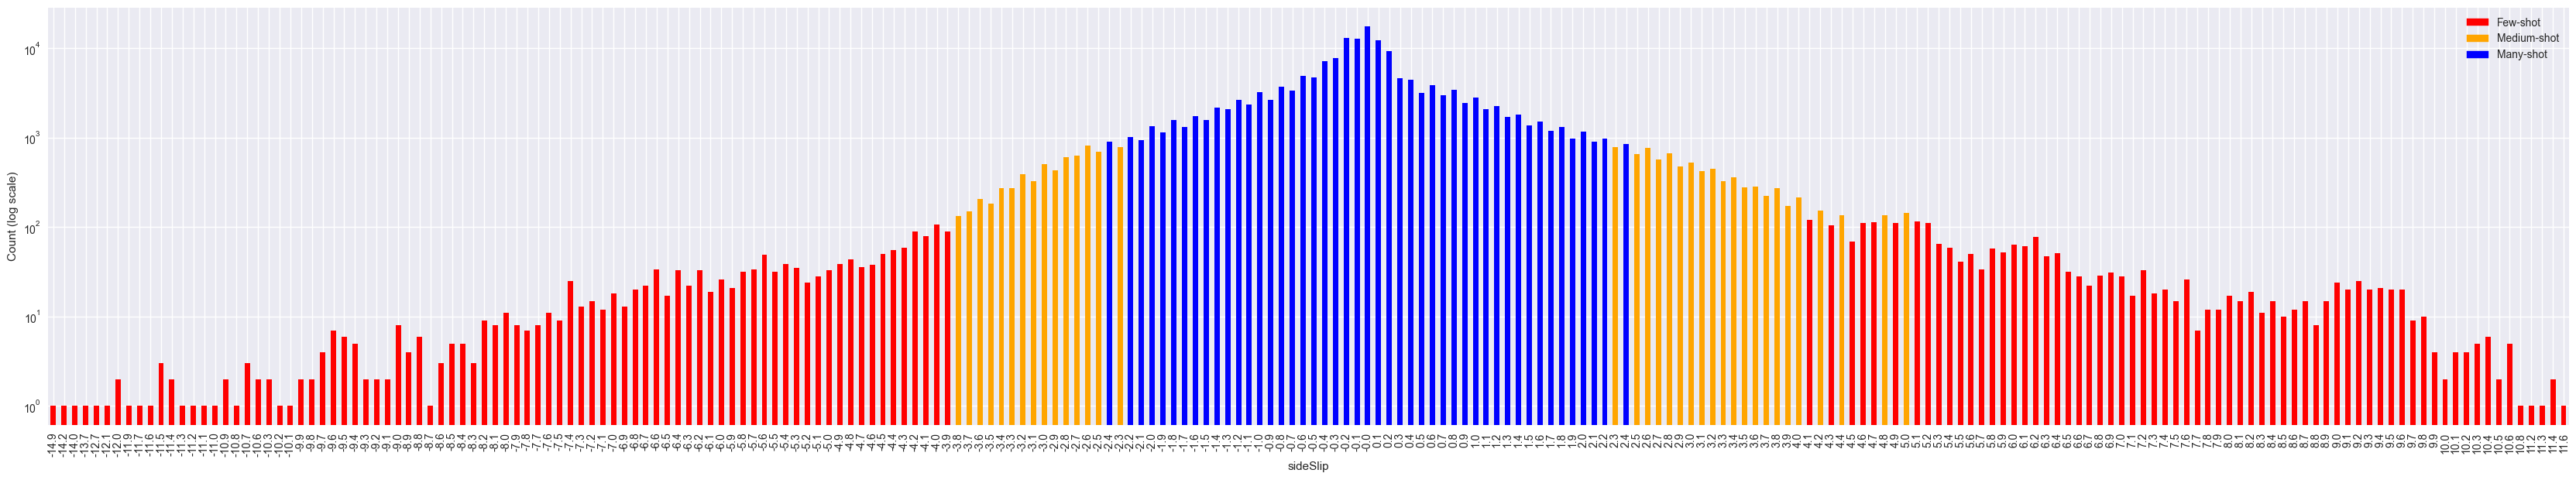

In [20]:
dist_df = pd.read_csv("datasets_challenge/sideSlip_distribution.csv")


import matplotlib.patches as mpatches
shot_band_mapping = dist_df.groupby("sideSlip")["band"].first()
colors = shot_band_mapping.map({"few": "red", "medium": "orange", "many": "blue"})
ax = dist_df.plot(x='sideSlip', y='count', kind='bar', figsize=(42, 7), fontsize=10, color=colors)
few_patch = mpatches.Patch(color='red', label='Few-shot')
medium_patch = mpatches.Patch(color='orange', label='Medium-shot')
many_patch = mpatches.Patch(color='blue', label='Many-shot')
ax.legend(handles=[few_patch, medium_patch, many_patch], loc='upper right')
plt.yscale('log')
plt.ylabel('Count (log scale)')
plt.show()

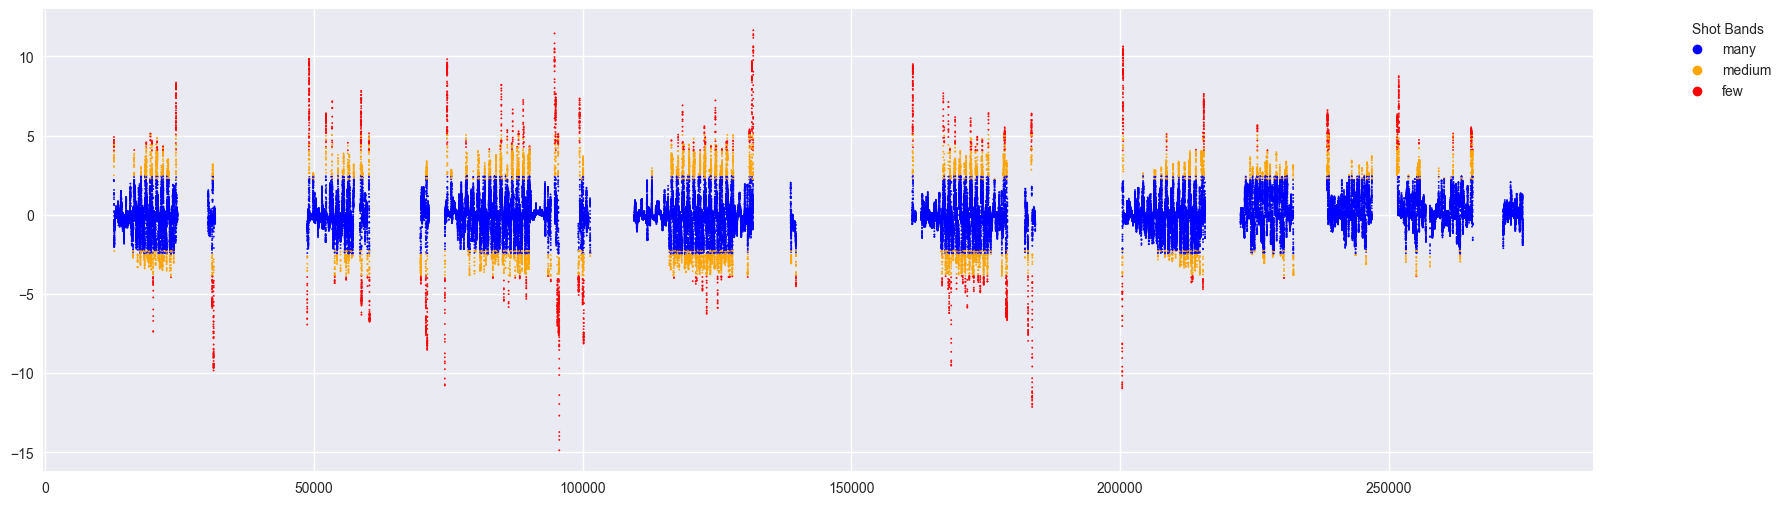

In [21]:
def concate_csv_dir(base_dir):
    all_dfs = []
    csv_lengths = {}
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            if file.endswith('.csv'):
                file_path = os.path.join(root, file)
                df = pd.read_csv(file_path)
                relative_path = os.path.relpath(file_path, base_dir)
                csv_lengths[relative_path] = len(df)
                all_dfs.append(df)
    
    return all_dfs, csv_lengths


df_list, csv_lengths = concate_csv_dir("datasets_challenge/train")
train_df = pd.concat(df_list, ignore_index=True)
train_df = train_df.where(train_df["vxCG"] > 3.0).dropna()  # Apply the same thresholding as during training


train_df["band"] = train_df["sideSlip"].round(1).map(shot_band_mapping)

plt.figure(figsize=(20, 6))
plt.scatter(train_df.index, train_df["sideSlip"], c=train_df["band"].map({"many": "blue", "medium": "orange", "few": "red"}), s=1)
# Plot the color code in a legend
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=7, label='many'),
                    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=7, label='medium'),
                    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=7, label='few')],
           title="Shot Bands", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [22]:
from utils.kaggle_metric import score

gt_df = pd.DataFrame({"ground_truth_sideslip": ground_truths}, dtype=np.float64)
gt_df["id"] = range(len(ground_truths))
gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")


preds_df = pd.DataFrame({"id": range(len(preds)), "predicted_sideslip": preds})

score(gt_df, preds_df, row_id_column_name="id")

band
few       0.300638
many      0.104930
medium    0.176704
Name: L1, dtype: float64